# 260901B2: omega dependence of the XRD pattern and origin of the 23 deg peak

Seven grazing-incidence 2-theta scans (omega = 0.1 to 1.1 deg, 20 to 35 deg 2-theta, identical counting time) of sample 260901B2, loaded from the NOMAD archives staged by notebook 1.

How omega is used to separate origins:
- **Film (BaCuSe layer) reflections**: intensity rises from 0.1 deg to about the critical angle, then stays roughly flat or grows slowly as the beam penetrates the whole film.
- **Surface species (oxide/selenate, top-layer Cu2Se)**: strongest at the lowest omega and fading in relative terms as the beam goes deeper.
- **Peak position vs omega**: a film reflection stays fixed in 2-theta in this geometry; shifts point to refraction/height errors rather than a new phase.

Intensities are raw counts per step; all scans use the same step (0.02 deg) and time per step, so absolute counts are comparable.

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

from striprtf.striprtf import rtf_to_text

from xrd_bo_optimization_tf.config import (
    FIGURES_DIR,
    MATCH_TOL,
    NOMAD_STAGING_DIR,
    REFERENCE_CARD_FILES,
    REFERENCES_DIR,
    RESULTS_DATA_DIR,
    TARGET_PHASE,
    XRD_PEAK_LIST_CSV,
)
from xrd_bo_optimization_tf.plotting import REFERENCE_COLORS
from xrd_bo_optimization_tf.peak_analysis import analyze_scan
from xrd_bo_optimization_tf.phase_matching import card_peak_rows
from xrd_bo_optimization_tf.xrd_io import load_xrd_data

SAMPLE = '260901B2'
UPLOAD = NOMAD_STAGING_DIR / 'TBRSU9POTmKRrd1aytChkA'
FOCUS_2THETA = 23.0
OUT_PREFIX = FIGURES_DIR / f'{SAMPLE}_omega'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
# Lower than the project's 10 % so the weak alpha (22.64, 4.6 %) and beta (23.01, 3.0 %) lines are included.
WEAK_REF_MIN_INTENSITY = 3.0
card_rows = {
    phase: card_peak_rows(rtf_to_text((REFERENCES_DIR / filename).read_text(encoding='utf-8', errors='replace')))
    for phase, filename in REFERENCE_CARD_FILES.items()
}
references = {
    phase: sorted({pos for pos, rel in rows if rel >= WEAK_REF_MIN_INTENSITY})
    for phase, rows in card_rows.items()
}


def read_result(path):
    data = json.loads(path.read_text(encoding='utf-8'))['data']
    result = data['results'][0]
    return {
        'name': data['name'],
        'omega': float(result['omega'][0]),
        'two_theta': np.asarray(result['two_theta'], dtype=float),
        'intensity': np.asarray(result['intensity'], dtype=float),
    }


# 'BCS I*' matches the result entries; the '.xrdml data file' entries use 'BCS_I'.
scans = sorted(
    (read_result(p) for p in UPLOAD.glob(f'{SAMPLE} BCS I* GI*.archive.json')),
    key=lambda s: s['omega'],
)
omegas = np.array([s['omega'] for s in scans])
two_theta = scans[0]['two_theta']
assert all(np.allclose(s['two_theta'], two_theta) for s in scans)
counts = np.vstack([s['intensity'] for s in scans])
print(pd.DataFrame({
    'entry': [s['name'] for s in scans],
    'omega_deg': omegas,
    'max_counts': counts.max(axis=1),
    'median_counts': np.median(counts, axis=1),
}).to_string(index=False))

                entry  omega_deg  max_counts  median_counts
 260901B2 BCS I2 GI01        0.1       179.0           42.5
 260901B2 BCS I4 GI02        0.2       279.0           54.0
 260901B2 BCS I6 GI03        0.3       189.0           66.0
 260901B2 BCS I8 GI05        0.5       281.0           50.0
260901B2 BCS I10 GI07        0.7       359.0           42.0
260901B2 BCS I12 GI09        0.9       446.0           38.0
260901B2 BCS I14 GI11        1.1       106.0           36.0


## 1. Stacked patterns with reference reflections

Vertical marks are ICDD reflections (>= `WEAK_REF_MIN_INTENSITY`, 3 %, instead of the project's 10 %) of each phase. Look at which phases have a line within the matching tolerance of the 23 deg peak.

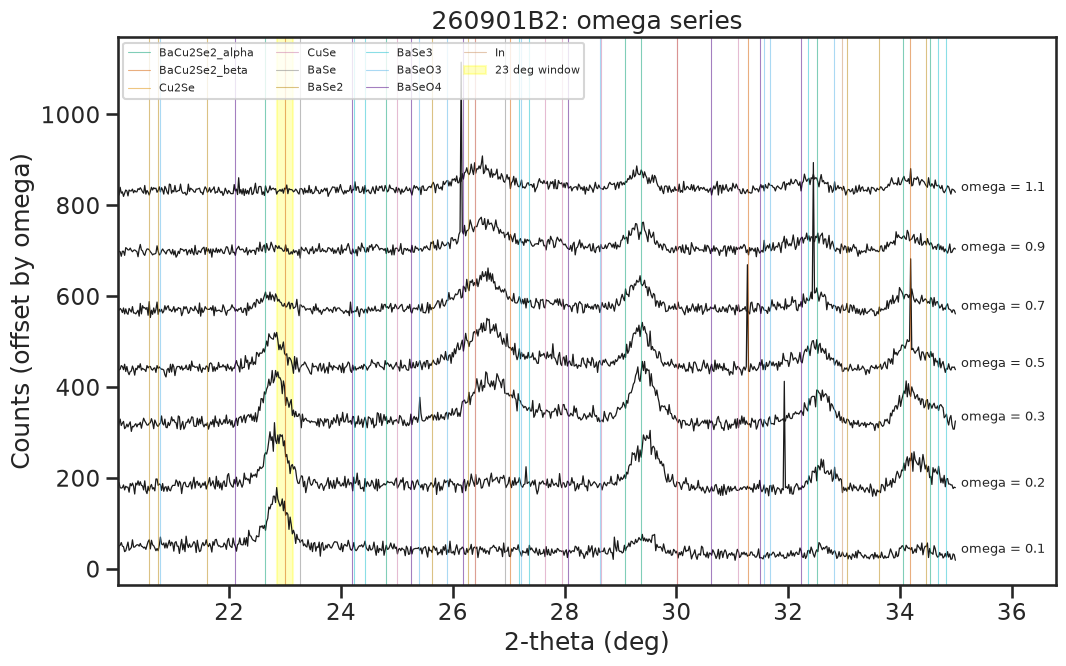

Reference reflections within 0.4 deg of 23.0 deg:
  BaCu2Se2_alpha: [22.637]
  BaCu2Se2_beta: [23.005]
  BaSe: [23.268]


In [2]:
phase_colors = REFERENCE_COLORS
lo, hi = two_theta.min(), two_theta.max()

fig, ax = plt.subplots(figsize=(11, 7))
offset = 0.6 * counts.max() / 2
for i, (omega, row) in enumerate(zip(omegas, counts)):
    ax.plot(two_theta, row + i * offset, lw=0.9, color='k')
    ax.text(hi + 0.1, i * offset + np.median(row), f'omega = {omega:.1f}', va='center', fontsize=9)
top = counts.max() + (len(omegas) - 1) * offset
for phase, positions in references.items():
    for j, pos in enumerate(p for p in positions if lo <= p <= hi):
        ax.axvline(pos, color=phase_colors.get(phase, 'gray'), lw=0.8, alpha=0.5,
                   label=phase if j == 0 else None)
ax.axvspan(FOCUS_2THETA - MATCH_TOL, FOCUS_2THETA + MATCH_TOL, color='yellow', alpha=0.25, label='23 deg window')
ax.set_xlim(lo, hi + 1.8)
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('Counts (offset by omega)')
ax.set_title(f'{SAMPLE}: omega series')
ax.legend(ncol=4, fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_stacked_patterns.png', dpi=200)
plt.show()

print(f'Reference reflections within 0.4 deg of {FOCUS_2THETA} deg:')
for phase, positions in references.items():
    near = [round(p, 3) for p in positions if abs(p - FOCUS_2THETA) <= 0.4]
    if near:
        print(f'  {phase}: {near}')

### Candidate lines near the 23 deg feature (all card intensities)

Matching in this notebook uses lines of at least 3 % (the project pipeline uses 10 %). The 23 deg feature falls on weak lines of the alpha and beta BaCu2Se2 cards (a few %), so every card line within the window is listed here regardless of intensity. A strong observed peak on a weak card line suggests preferred orientation (texture) of that phase.

In [3]:
WINDOW = (22.2, 23.6)
card_lines = []
for phase, filename in REFERENCE_CARD_FILES.items():
    text = rtf_to_text((REFERENCES_DIR / filename).read_text(encoding='utf-8', errors='replace'))
    for position, rel_intensity in card_peak_rows(text):
        if WINDOW[0] <= position <= WINDOW[1]:
            card_lines.append({'phase': phase, 'card': filename.split(' ')[0],
                               'two_theta': position, 'rel_intensity_pct': rel_intensity})
card_lines = pd.DataFrame(card_lines).sort_values('two_theta')
card_lines['delta_to_observed'] = card_lines['two_theta'] - 22.81
card_lines.round(3).reset_index(drop=True)

,phase,card,two_theta,rel_intensity_pct,delta_to_observed
0,BaCu2Se2_alpha,01-080-2950,22.637,4.6,-0.173
1,BaCu2Se2_beta,04-008-2861,23.005,3.0,0.195
2,BaSeO4,04-011-7418,23.172,1.4,0.362
3,BaSe,01-071-4770,23.268,13.5,0.458


## 2. Intensity map (omega vs 2-theta)

A film reflection appears as a vertical stripe with intensity that builds up above the critical angle.

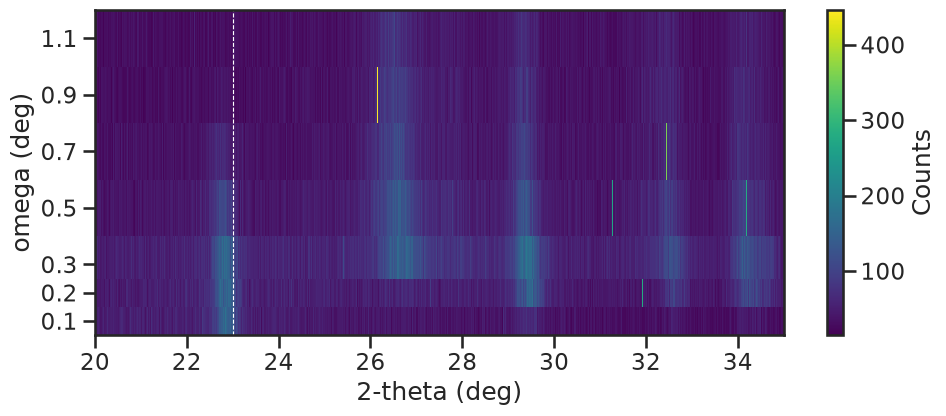

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
mesh = ax.pcolormesh(two_theta, omegas, counts, shading='nearest', cmap='viridis')
ax.set_yticks(omegas)
ax.axvline(FOCUS_2THETA, color='w', ls='--', lw=0.8)
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('omega (deg)')
fig.colorbar(mesh, label='Counts')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_intensity_map.png', dpi=200)
plt.show()

## 3. Peak list from the omega-summed pattern

Peaks are detected on the sum of all omegas (best signal) with the project's standard preprocessing, then matched to reference cards within the project tolerance, using the lowered 3 % intensity threshold so the weak alpha/beta BaCu2Se2 lines near 23 deg can match. The table shows the offset to the card line and its relative intensity. The 23 deg peak is always tracked, even if it falls below the detection threshold.

In [5]:
summed = counts.sum(axis=0)
summed_result = analyze_scan(two_theta, summed)
peak_positions = list(two_theta[summed_result['detected_peaks']])

window = (two_theta > FOCUS_2THETA - 0.5) & (two_theta < FOCUS_2THETA + 0.5)
focus_center = float(two_theta[window][np.argmax(summed_result['smooth'][window])])
if not any(abs(p - focus_center) < 0.15 for p in peak_positions):
    peak_positions.append(focus_center)
peak_positions = sorted(peak_positions)


def match_phases(position, tolerance=MATCH_TOL):
    hits = []
    for phase, rows in card_rows.items():
        lines = [(pos, rel) for pos, rel in rows if rel >= WEAK_REF_MIN_INTENSITY]
        pos, rel = min(lines, key=lambda line: abs(line[0] - position))
        if abs(pos - position) <= tolerance:
            hits.append(f'{phase} ({pos - position:+.2f}, {rel:.0f}%)')
    return ', '.join(hits) if hits else 'unmatched'


peak_table = pd.DataFrame({
    'two_theta': np.round(peak_positions, 3),
    'matches (delta to card, rel. intensity)': [match_phases(p) for p in peak_positions],
})
peak_table['focus'] = np.isclose(peak_table['two_theta'], focus_center, atol=0.01)
peak_table

,two_theta,"matches (delta to card, rel. intensity)",focus
0,22.81,unmatched,True
1,26.59,unmatched,False
2,29.41,"BaCu2Se2_alpha (-0.04, 100%)",False
3,32.53,"BaCu2Se2_alpha (-0.02, 39%)",False
4,34.15,"BaCu2Se2_alpha (-0.09, 69%), BaCu2Se2_beta (+0...",False


## 4. Peak fits per omega

Each tracked peak is fitted with a Gaussian plus linear background in a +/-0.35 deg window, weighted by counting (Poisson) errors. Reported: net area, centre, FWHM, and their uncertainties.

In [6]:
def gauss_linear(x, amp, center, sigma, b0, b1, x0):
    return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + b0 + b1 * (x - x0)


def fit_peak(x_all, y_all, center, half_width=0.35):
    mask = (x_all >= center - half_width) & (x_all <= center + half_width)
    x, y = x_all[mask], y_all[mask]
    model = lambda xx, a, c, s, b0, b1: gauss_linear(xx, a, c, s, b0, b1, center)
    p0 = [max(y.max() - np.median(y), 1.0), center, 0.08, float(np.median(y)), 0.0]
    lower = [0, center - 0.2, 0.02, -np.inf, -np.inf]
    upper = [np.inf, center + 0.2, 0.5, np.inf, np.inf]
    try:
        popt, pcov = curve_fit(model, x, y, p0=p0, bounds=(lower, upper),
                               sigma=np.sqrt(np.clip(y, 1, None)), absolute_sigma=True)
    except (RuntimeError, ValueError):
        return dict.fromkeys(['area', 'area_err', 'center', 'center_err', 'fwhm', 'fwhm_err', 'height'], np.nan)
    amp, cen, sig = popt[:3]
    area_var = 2 * np.pi * (sig ** 2 * pcov[0, 0] + amp ** 2 * pcov[2, 2] + 2 * amp * sig * pcov[0, 2])
    area_err = float(np.sqrt(max(area_var, 0.0)))
    return {
        'area': amp * sig * np.sqrt(2 * np.pi),
        'area_err': area_err,
        'center': cen,
        'center_err': float(np.sqrt(pcov[1, 1])),
        'fwhm': 2.3548 * sig,
        'fwhm_err': 2.3548 * float(np.sqrt(pcov[2, 2])),
        'height': amp,
    }


records = []
for omega, row in zip(omegas, counts):
    clean = analyze_scan(two_theta, row)['cleaned']
    for position in peak_positions:
        fit = fit_peak(two_theta, clean, position)
        records.append({'omega': omega, 'peak': round(position, 2), **fit})
fits = pd.DataFrame(records)
fits['significant'] = fits['area'] > 3 * fits['area_err']  # area > 3 sigma
fits.to_csv(RESULTS_DATA_DIR / f'{SAMPLE}_omega_peak_fits.csv', index=False)
fits.pivot(index='peak', columns='omega', values='area').round(1)

omega,0.1,0.2,0.3,0.5,0.7,0.9,1.1
peak,,,,,,,
22.81,41.1,45.7,52.1,41.3,8.5,72.5,0.5
26.59,0.9,NaN,166.3,33.7,8.0,140.6,3.2
29.41,80.3,72.2,53.8,26.3,21.3,143.7,171.1
32.53,9.5,10.9,42.9,16.2,10.2,109.6,22.1
34.15,1.9,15.6,26.3,11.3,5.5,10.3,18.0


## 5. Intensity vs omega for each peak

Left: net area. Right: area normalised to its maximum, which makes the shape of the omega dependence comparable between peaks. The 23 deg peak is the thick black line.

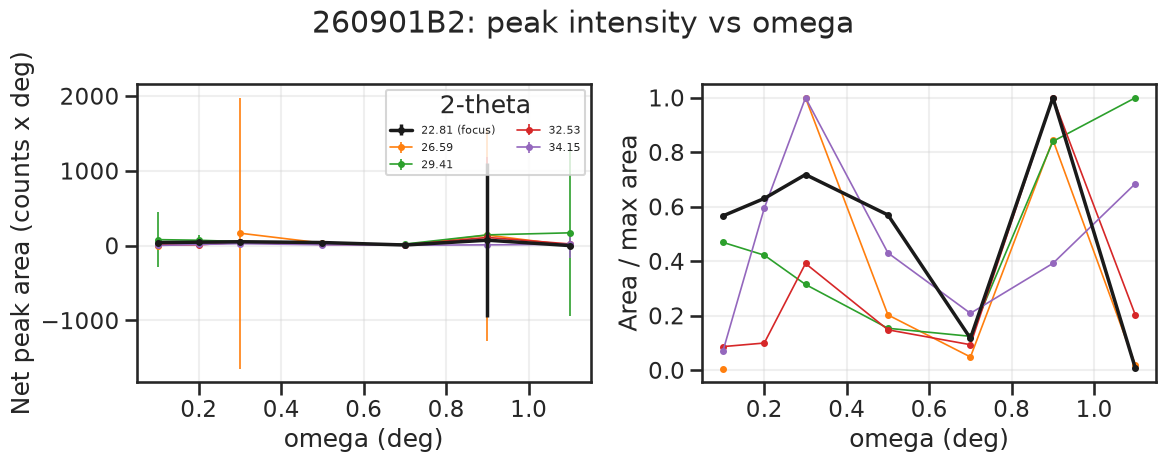

In [7]:
focus_label = round(focus_center, 2)
cmap = plt.get_cmap('tab10')
fig, (ax_abs, ax_norm) = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for k, (peak, group) in enumerate(fits.groupby('peak')):
    group = group.sort_values('omega')
    is_focus = peak == focus_label
    style = dict(color='k', lw=2.5, zorder=5) if is_focus else dict(color=cmap(k % 10), lw=1.2)
    label = f'{peak:.2f}' + (' (focus)' if is_focus else '')
    ax_abs.errorbar(group['omega'], group['area'], yerr=group['area_err'], marker='o', ms=4, label=label, **style)
    top = group['area'].max()
    if np.isfinite(top) and top > 0:
        ax_norm.plot(group['omega'], group['area'] / top, marker='o', ms=4, **style)
ax_abs.set_ylabel('Net peak area (counts x deg)')
ax_norm.set_ylabel('Area / max area')
for ax in (ax_abs, ax_norm):
    ax.set_xlabel('omega (deg)')
    ax.grid(alpha=0.3)
ax_abs.legend(title='2-theta', fontsize=8, ncol=2)
fig.suptitle(f'{SAMPLE}: peak intensity vs omega')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_peak_intensity_vs_omega.png', dpi=200)
plt.show()

## 6. Position and width of the 23 deg peak vs omega, and sharpness

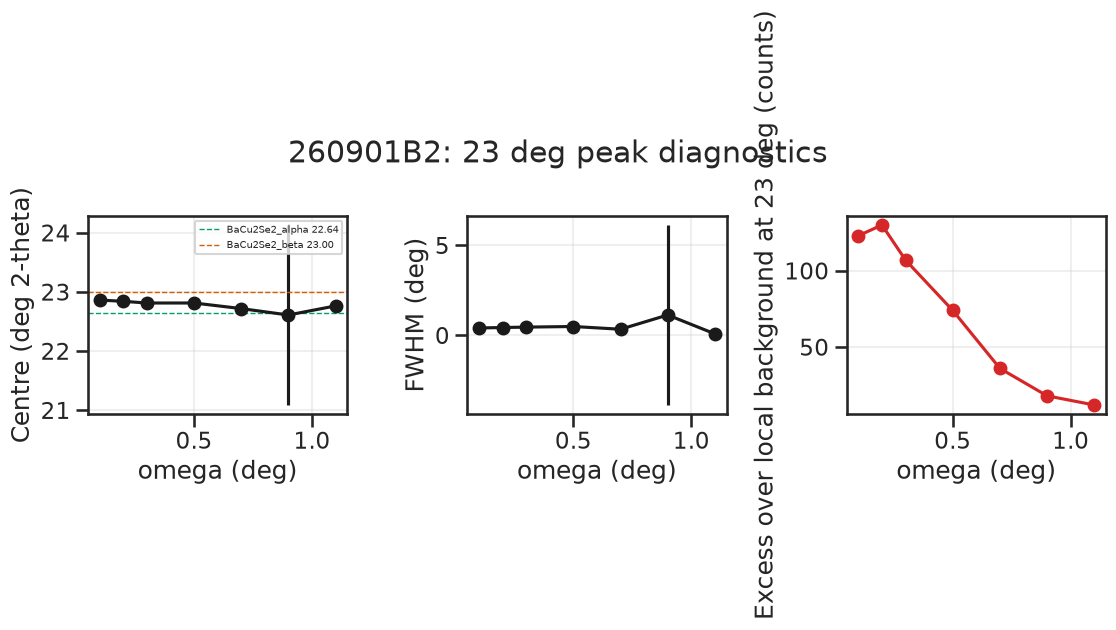

,omega,peak,area,area_err,center,center_err,fwhm,fwhm_err,height,significant
0,0.1,22.81,41.091,12.117,22.862,0.017,0.406,0.064,94.984,True
5,0.2,22.81,45.721,14.375,22.841,0.017,0.432,0.071,99.431,True
10,0.3,22.81,52.086,16.560,22.812,0.016,0.455,0.076,107.628,True
15,0.5,22.81,41.321,17.965,22.813,0.021,0.488,0.107,79.477,False
20,0.7,22.81,8.461,6.036,22.718,0.040,0.337,0.129,23.597,False
25,0.9,22.81,72.547,1028.156,22.610,1.521,1.128,4.999,60.423,False
30,1.1,22.81,0.482,0.401,22.763,0.029,0.080,0.069,5.628,False


In [8]:
focus = fits[fits['peak'] == focus_label].sort_values('omega')

from scipy.ndimage import median_filter
sharp = np.array([
    (row - median_filter(row, size=151, mode='nearest'))[(two_theta > FOCUS_2THETA - 0.3) & (two_theta < FOCUS_2THETA + 0.3)].max()
    for row in counts
])

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.8))
axes[0].errorbar(focus['omega'], focus['center'], yerr=focus['center_err'], marker='o', color='k')
for _, line in card_lines[card_lines['phase'].isin([TARGET_PHASE, 'BaCu2Se2_beta'])].iterrows():
    axes[0].axhline(line['two_theta'], color=phase_colors[line['phase']], ls='--', lw=1,
                    label=f"{line['phase']} {line['two_theta']:.2f}")
axes[0].legend(fontsize=7)
axes[0].set_ylabel('Centre (deg 2-theta)')
axes[1].errorbar(focus['omega'], focus['fwhm'], yerr=focus['fwhm_err'], marker='o', color='k')
axes[1].set_ylabel('FWHM (deg)')
axes[2].plot(omegas, sharp, marker='o', color='tab:red')
axes[2].set_ylabel('Excess over local background at 23 deg (counts)')
for ax in axes:
    ax.set_xlabel('omega (deg)')
    ax.grid(alpha=0.3)
fig.suptitle(f'{SAMPLE}: 23 deg peak diagnostics')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_focus_peak_diagnostics.png', dpi=200)
plt.show()
focus.round(3)

## 7. Ratios to the alpha-BaCu2Se2 reflections

If the 23 deg peak belongs to the BaCuSe layer, its ratio to the film reflections should be roughly constant with omega. A rising or falling ratio points to a species at a different depth.

alpha-BaCu2Se2-matched peaks used as denominator: [np.float64(29.41), np.float64(32.53), np.float64(34.15)]


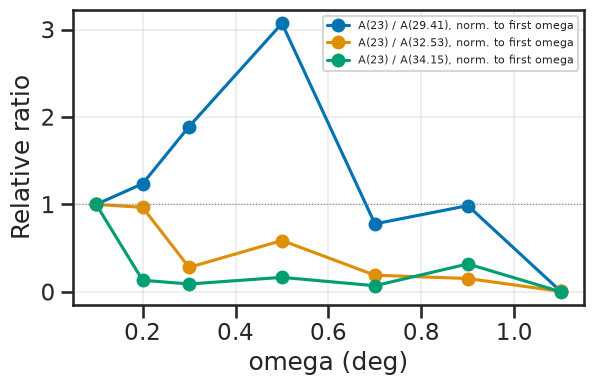

In [9]:
target_peaks = [round(p, 2) for p in peak_positions
                if TARGET_PHASE in match_phases(p) and round(p, 2) != focus_label]
print('alpha-BaCu2Se2-matched peaks used as denominator:', target_peaks)

pivot = fits.pivot(index='omega', columns='peak', values='area')
if target_peaks:
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for peak in target_peaks:
        ratio = pivot[focus_label] / pivot[peak]
        ax.plot(pivot.index, ratio / ratio.dropna().iloc[0], marker='o', label=f'A(23) / A({peak:.2f}), norm. to first omega')
    ax.axhline(1, color='gray', lw=0.8, ls=':')
    ax.set_xlabel('omega (deg)')
    ax.set_ylabel('Relative ratio')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f'{OUT_PREFIX}_focus_ratio_to_film_peaks.png', dpi=200)
    plt.show()

## 8. Is the 23 deg feature present in the other 260901 samples (GI 0.2 deg)?

The SLG substrate has no sharp peak at 23 deg, so the feature belongs to the film side. A height that follows the BaCuSe content or composition points to the layer itself; a height that follows selenization conditions or aging points to an impurity or secondary phase. The new SLG scans (260901A1, A2, A4) are included.

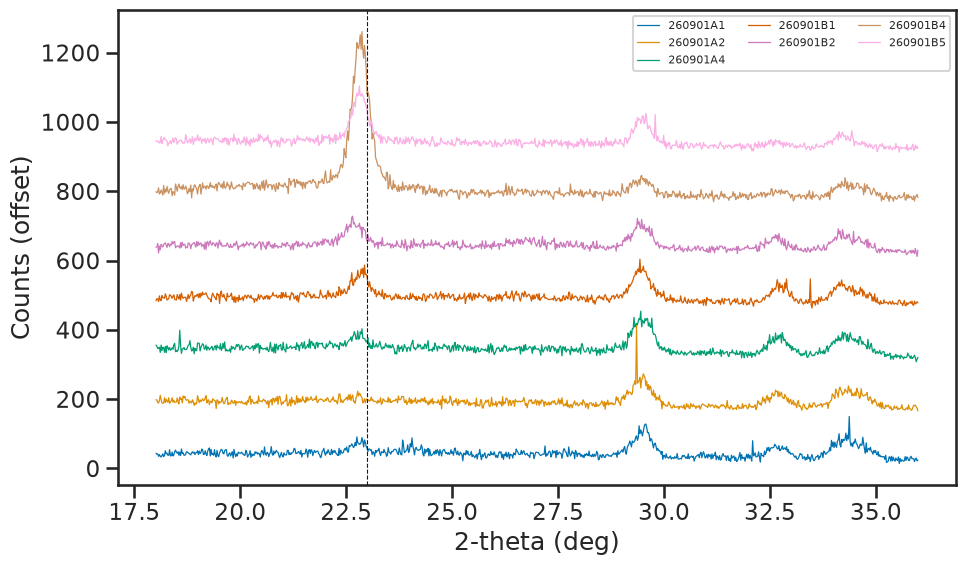

,sample,excess_at_23_over_20-22.5_median,peak_position
0,260901A1,47.0,22.8
1,260901A2,28.0,22.8
2,260901A4,52.0,22.9
3,260901B1,89.0,22.9
4,260901B2,61.0,22.8
5,260901B4,437.0,22.9
6,260901B5,155.0,22.8


In [10]:
def load_gi02(name_glob):
    out = {}
    for path in sorted(UPLOAD.glob(name_glob)):
        if 'xrdml' in path.name or 'processing' in path.name:
            continue
        data = json.loads(path.read_text(encoding='utf-8'))['data']
        if not data.get('results'):
            continue
        result = data['results'][0]
        if abs(result['omega'][0] - 0.2) > 1e-6 or len(result['two_theta']) < 2000:
            continue
        out[data['name'].split()[0]] = (np.asarray(result['two_theta']), np.asarray(result['intensity']))
    return out


gi02 = {**load_gi02('260901A* GI02.archive.json'), **load_gi02('260901B* GI02.archive.json')}
fig, ax = plt.subplots(figsize=(10, 6))
rows = []
for i, (sample, (tt, yy)) in enumerate(sorted(gi02.items())):
    sel = (tt >= 18) & (tt <= 36)
    ax.plot(tt[sel], yy[sel] + i * 150, lw=0.9, label=sample)
    near = (tt > FOCUS_2THETA - 0.3) & (tt < FOCUS_2THETA + 0.3)
    base = np.median(yy[(tt > 20) & (tt < 22.5)])
    rows.append({'sample': sample, 'excess_at_23_over_20-22.5_median': float(yy[near].max() - base),
                 'peak_position': float(tt[near][np.argmax(yy[near])])})
ax.axvline(FOCUS_2THETA, color='k', ls='--', lw=0.8)
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('Counts (offset)')
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_other_samples_gi02.png', dpi=200)
plt.show()
pd.DataFrame(rows).round(1)

### Position of the 23 deg feature across all analyzed films

Peak positions from the classified peak list of notebook 2, grouped by series, compared with the weak alpha (22.637 deg) and beta (23.005 deg) BaCu2Se2 lines. A series sitting closer to one line than the other points to that polymorph; a spread between the two points to a mixture or to a position shift.

alpha line 22.637, beta line 23.005 deg


,n_films,mean_2theta,std_2theta,mean_fwhm,delta_to_alpha,delta_to_beta,closer_to
series,,,,,,,
260429A,4,22.975,0.157,0.595,0.338,-0.030,beta
260429B,3,22.910,0.020,0.531,0.273,-0.095,beta
260429C,3,22.863,0.012,0.413,0.226,-0.142,beta
260721D,7,22.899,0.032,0.406,0.262,-0.106,beta
260901A,3,22.857,0.042,0.423,0.220,-0.148,beta
260901B,4,22.805,0.094,0.421,0.168,-0.200,alpha
260908B,1,22.830,NaN,0.404,0.193,-0.175,beta
260929A,3,22.683,0.076,0.446,0.046,-0.322,alpha


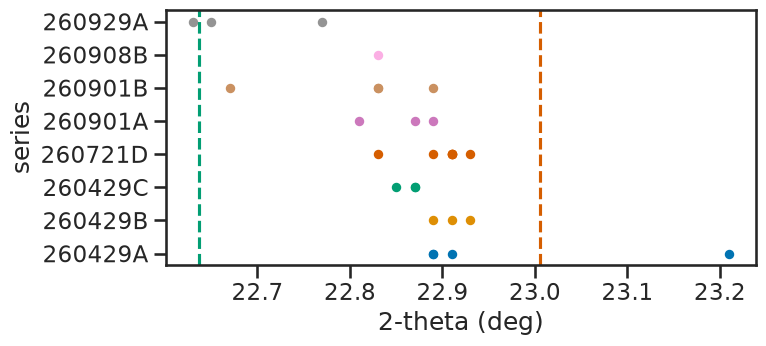

In [11]:
from xrd_bo_optimization_tf.config import XRD_PEAK_LIST_CSV

alpha_line = card_lines.loc[card_lines['phase'] == TARGET_PHASE, 'two_theta'].iloc[0]
beta_line = card_lines.loc[card_lines['phase'] == 'BaCu2Se2_beta', 'two_theta'].iloc[0]

peak_list = pd.read_csv(XRD_PEAK_LIST_CSV)
near_23 = peak_list[peak_list['two_theta_deg'].between(22.4, 23.4)].copy()
near_23['delta_alpha'] = near_23['two_theta_deg'] - alpha_line
near_23['delta_beta'] = near_23['two_theta_deg'] - beta_line
summary = near_23.groupby('series').agg(
    n_films=('sample_id', 'nunique'),
    mean_2theta=('two_theta_deg', 'mean'),
    std_2theta=('two_theta_deg', 'std'),
    mean_fwhm=('fwhm_deg', 'mean'),
    delta_to_alpha=('delta_alpha', 'mean'),
    delta_to_beta=('delta_beta', 'mean'),
)
summary['closer_to'] = np.where(summary['delta_to_alpha'].abs() < summary['delta_to_beta'].abs(), 'alpha', 'beta')
print(f'alpha line {alpha_line:.3f}, beta line {beta_line:.3f} deg')
display(summary.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
for series, group in near_23.groupby('series'):
    ax.scatter(group['two_theta_deg'], [series] * len(group), s=28, label=series)
ax.axvline(alpha_line, color=phase_colors[TARGET_PHASE], ls='--', label='alpha line')
ax.axvline(beta_line, color=phase_colors['BaCu2Se2_beta'], ls='--', label='beta line')
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('series')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_position_by_series.png', dpi=200)
plt.show()

## 9. Telling alpha from beta BaCu2Se2

The two cards are different structures: alpha is orthorhombic (Pnma) and beta is tetragonal (I4/mmm). The 23 deg feature is alpha (011) at 22.637 deg or beta (101) at 23.005 deg, both weak in a random powder (4.6 % and 3.0 %).

The decisive test uses the **other** reflections of each polymorph. A phase that gives a strong 23 deg peak should also show its own strong lines, at least in proportion to the card unless the film is textured. Lines unique to one polymorph (no line of the other card within 0.3 deg) are used:
- alpha: (211) 29.37 deg (100 %), (302) 32.51 deg, (113) 34.06 deg
- beta: (103) 30.02 deg (100 %), (110) 31.29 deg

For the films with the strongest 23 deg peak, the cell below measures the height at each unique line, the signal-to-noise ratio, and the observed/expected height, where expected = (23 deg peak height) x (card intensity of the line / card intensity of the 23 deg line of that phase). Observed/expected well below 1 with a clear signal means a textured film; no signal at the strongest unique line means that polymorph is probably absent.

In [12]:
OTHER = {TARGET_PHASE: 'BaCu2Se2_beta', 'BaCu2Se2_beta': TARGET_PHASE}
LINE_23 = {phase: min(card_rows[phase], key=lambda row: abs(row[0] - FOCUS_2THETA)) for phase in OTHER}


def exclusive_lines(phase, min_pct=8.0, clearance=0.3, lo=10.0, hi=60.0):
    # Lines of `phase` with no line of the other polymorph within `clearance` deg.
    other_positions = [pos for pos, rel in card_rows[OTHER[phase]] if rel >= 1.0]
    lines = {pos: rel for pos, rel in card_rows[phase] if rel >= min_pct and lo <= pos <= hi}
    return {pos: rel for pos, rel in lines.items() if all(abs(pos - q) > clearance for q in other_positions)}


for phase in OTHER:
    print(phase, '23 deg line:', LINE_23[phase], '| exclusive lines (2theta: %):', exclusive_lines(phase))

# Films with the strongest 23 deg peak in the classified peak list of notebook 2.
peak_list = pd.read_csv(XRD_PEAK_LIST_CSV)
near_23_peaks = peak_list[peak_list['two_theta_deg'].between(22.4, 23.4)]
top_samples = (near_23_peaks.sort_values('detected_intensity', ascending=False)
               .drop_duplicates('sample_id')['sample_id'].head(8).tolist())
top_scans = load_xrd_data(top_samples, source='nomad', nomad_archive_root=NOMAD_STAGING_DIR)


def height_and_noise(tt, intensity, position, half_window=0.15):
    result = analyze_scan(tt, intensity)
    residual = result['bg_removed'] - result['smooth']
    noise = 1.4826 * np.median(np.abs(residual - np.median(residual)))
    mask = np.abs(tt - position) <= half_window
    return (float(result['smooth'][mask].max()) if mask.any() else np.nan), float(noise)


rows = []
for sample_id in top_samples:
    tt, yy = top_scans[sample_id]['two_theta'], top_scans[sample_id]['intensity']
    h23, noise = height_and_noise(tt, yy, near_23_peaks.loc[near_23_peaks['sample_id'] == sample_id, 'two_theta_deg'].iloc[0])
    for phase in OTHER:
        pos23, rel23 = LINE_23[phase]
        for pos, rel in exclusive_lines(phase).items():
            if not tt.min() <= pos <= tt.max():
                continue
            height, _ = height_and_noise(tt, yy, pos)
            expected = h23 * rel / rel23
            rows.append({'sample': sample_id, 'phase': phase, 'line_2theta': pos, 'card_pct': rel,
                         'height_23': h23, 'expected': expected, 'observed': height,
                         'snr': height / noise, 'obs_over_expected': height / expected})
discrimination = pd.DataFrame(rows)
discrimination.round(2)

BaCu2Se2_alpha 23 deg line: (22.637, 4.6) | exclusive lines (2theta: %): {29.084: 12.3, 29.372: 100.0, 32.512: 38.7, 34.529: 30.0, 42.89: 30.4, 46.662: 11.8, 51.205: 10.0, 56.186: 11.7}
BaCu2Se2_beta 23 deg line: (23.005, 3.0) | exclusive lines (2theta: %): {30.019: 100.0, 41.81: 12.5, 44.833: 34.7}


,sample,phase,line_2theta,card_pct,height_23,expected,observed,snr,obs_over_expected
0,260721D11,BaCu2Se2_alpha,29.08,12.3,354.20,947.09,68.29,10.18,0.07
1,260721D11,BaCu2Se2_alpha,29.37,100.0,354.20,7699.92,145.36,21.66,0.02
2,260721D11,BaCu2Se2_alpha,32.51,38.7,354.20,2979.87,71.14,10.60,0.02
3,260721D11,BaCu2Se2_alpha,34.53,30.0,354.20,2309.98,75.52,11.26,0.03
4,260721D11,BaCu2Se2_alpha,42.89,30.4,354.20,2340.78,50.45,7.52,0.02
...,...,...,...,...,...,...,...,...,...
83,260721D3,BaCu2Se2_alpha,51.20,10.0,192.46,418.40,18.51,2.78,0.04
84,260721D3,BaCu2Se2_alpha,56.19,11.7,192.46,489.53,15.85,2.38,0.03
85,260721D3,BaCu2Se2_beta,30.02,100.0,192.46,6415.44,50.96,7.66,0.01
86,260721D3,BaCu2Se2_beta,41.81,12.5,192.46,801.93,45.07,6.77,0.06


In [13]:
summary = (discrimination.sort_values('card_pct', ascending=False)
           .groupby(['sample', 'phase']).first()[['line_2theta', 'card_pct', 'snr', 'obs_over_expected']]
           .round(2))
print('Strongest exclusive line of each polymorph per film')
summary

Strongest exclusive line of each polymorph per film


line_2theta  card_pct    snr  obs_over_expected
sample    phase                                                          
260429A11 BaCu2Se2_alpha        29.37     100.0  10.98               0.02
          BaCu2Se2_beta         30.02     100.0   4.09               0.00
260429A12 BaCu2Se2_alpha        29.37     100.0   6.30               0.01
          BaCu2Se2_beta         30.02     100.0   3.38               0.00
260429C3  BaCu2Se2_alpha        29.37     100.0   5.35               0.00
          BaCu2Se2_beta         30.02     100.0   3.11               0.00
260721D1  BaCu2Se2_alpha        29.37     100.0  23.00               0.03
          BaCu2Se2_beta         30.02     100.0   6.48               0.01
260721D11 BaCu2Se2_alpha        29.37     100.0  21.66               0.02
          BaCu2Se2_beta         30.02     100.0   5.21               0.00
260721D2  BaCu2Se2_alpha        29.37     100.0  19.31               0.03
          BaCu2Se2_beta         30.02     100.0   5.89               0.01
260721D3  BaCu2Se2_alpha        29.37     100.0   6.52               0.01
          BaCu2Se2_beta         30.02     100.0   7.66               0.01
260901B4  BaCu2Se2_alpha        29.37     100.0   9.17               0.01
          BaCu2Se2_beta         30.02     100.0   3.61               0.00

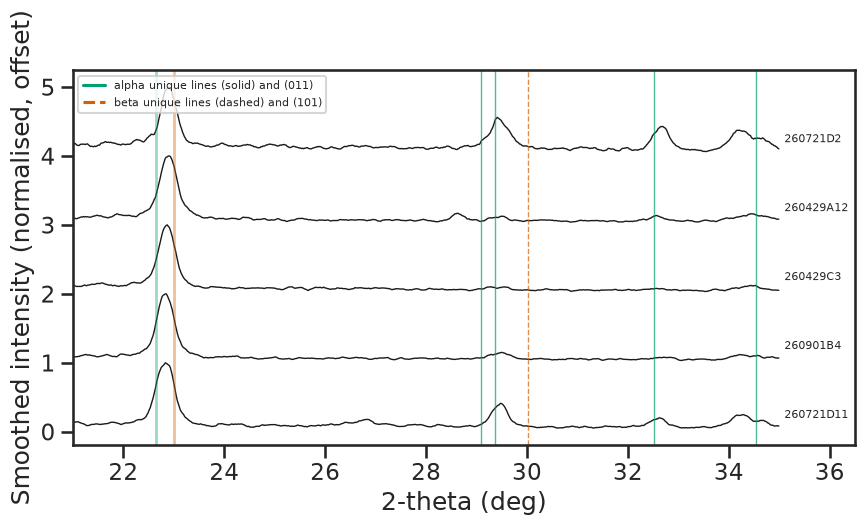

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
for k, sample_id in enumerate(top_samples[:5]):
    tt, yy = top_scans[sample_id]['two_theta'], top_scans[sample_id]['intensity']
    smooth = analyze_scan(tt, yy)['smooth']
    mask = (tt >= 21) & (tt <= 35)
    ax.plot(tt[mask], smooth[mask] / smooth[mask].max() + k, lw=1, color='k')
    ax.text(35.1, k + 0.2, sample_id, fontsize=8)
for pos in exclusive_lines(TARGET_PHASE):
    ax.axvline(pos, color=phase_colors[TARGET_PHASE], lw=1, alpha=0.7)
for pos in exclusive_lines('BaCu2Se2_beta'):
    ax.axvline(pos, color=phase_colors['BaCu2Se2_beta'], lw=1, ls='--', alpha=0.7)
ax.axvline(LINE_23[TARGET_PHASE][0], color=phase_colors[TARGET_PHASE], lw=2, alpha=0.4)
ax.axvline(LINE_23['BaCu2Se2_beta'][0], color=phase_colors['BaCu2Se2_beta'], lw=2, alpha=0.4)
ax.plot([], [], color=phase_colors[TARGET_PHASE], label='alpha unique lines (solid) and (011)')
ax.plot([], [], color=phase_colors['BaCu2Se2_beta'], ls='--', label='beta unique lines (dashed) and (101)')
ax.set_xlim(21, 36.5)
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('Smoothed intensity (normalised, offset)')
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_alpha_vs_beta_unique_lines.png', dpi=200)
plt.show()

### Second-order test

If the 23 deg peak is a strongly textured family, the second order of the same plane (alpha (022), beta (202)) must appear at the position from half the d-spacing, and the two polymorphs predict positions about 0.8 deg apart. The card d-spacings are halved and converted with Cu K-alpha1 (1.5406 A). Only the full-range 10-60 deg scans can show this.

{'BaCu2Se2_alpha': np.float64(46.22), 'BaCu2Se2_beta': np.float64(47.01)}


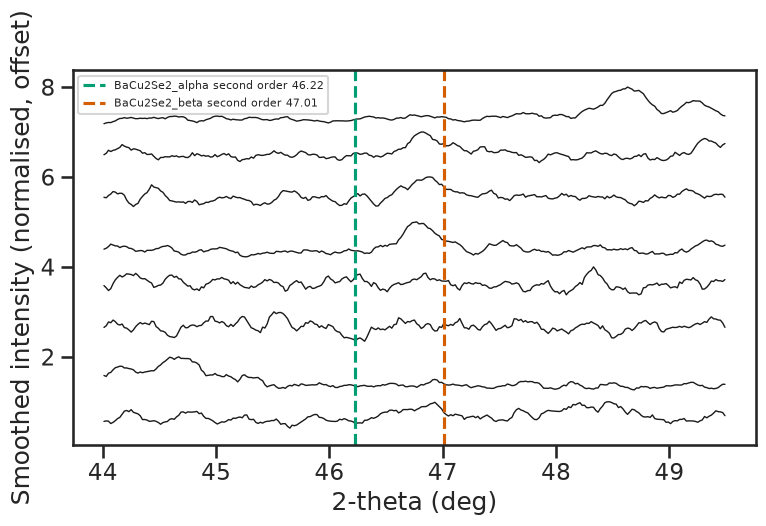

SNR at second order,BaCu2Se2_alpha,BaCu2Se2_beta
sample,,
260429A11,2.9,4.5
260429A12,2.6,2.7
260429C3,1.8,2.3
260721D1,2.6,4.9
260721D11,3.1,4.8
260721D2,2.5,5.4
260721D3,3.3,3.4
260901B4,2.4,3.1


In [15]:
WAVELENGTH = 1.5406
second_order = {
    phase: 2 * np.degrees(np.arcsin(WAVELENGTH / (2 * (WAVELENGTH / (2 * np.sin(np.radians(LINE_23[phase][0] / 2))) / 2))))
    for phase in OTHER
}
print({phase: round(pos, 2) for phase, pos in second_order.items()})

rows = []
fig, ax = plt.subplots(figsize=(8, 5))
for k, sample_id in enumerate(top_samples):
    tt, yy = top_scans[sample_id]['two_theta'], top_scans[sample_id]['intensity']
    if tt.max() < 48:
        continue
    result = analyze_scan(tt, yy)
    noise = 1.4826 * np.median(np.abs(result['bg_removed'] - result['smooth'] - np.median(result['bg_removed'] - result['smooth'])))
    for phase, pos in second_order.items():
        mask = np.abs(tt - pos) <= 0.2
        rows.append({'sample': sample_id, 'phase': phase, 'second_order_2theta': round(pos, 2),
                     'height': float(result['smooth'][mask].max()), 'snr': float(result['smooth'][mask].max() / noise)})
    window = (tt >= 44) & (tt <= 49.5)
    ax.plot(tt[window], result['smooth'][window] / max(result['smooth'][window].max(), 1e-9) + k, lw=1, color='k')
for phase, pos in second_order.items():
    ax.axvline(pos, color=phase_colors[phase], ls='--', label=f'{phase} second order {pos:.2f}')
ax.set_xlabel('2-theta (deg)')
ax.set_ylabel('Smoothed intensity (normalised, offset)')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f'{OUT_PREFIX}_second_order_test.png', dpi=200)
plt.show()
pd.DataFrame(rows).pivot(index='sample', columns='phase', values='snr').round(1).rename_axis(columns='SNR at second order')

### d-spacing from the first and second order

The second-order peak sits at higher angle, where a sample-height or refraction offset changes d much less than at 23 deg. The d-spacing of the family follows from the second-order position as d = 2 x d(second order), and is compared with the card values alpha (011) 3.925 A and beta (101) 3.863 A. A first-order and second-order pair with d1/d2 = 2 confirms they belong to one family of planes.

In [16]:
def d_spacing(two_theta_deg):
    return WAVELENGTH / (2 * np.sin(np.radians(two_theta_deg / 2)))


card_d = {
    TARGET_PHASE: WAVELENGTH / (2 * np.sin(np.radians(LINE_23[TARGET_PHASE][0] / 2))),
    'BaCu2Se2_beta': WAVELENGTH / (2 * np.sin(np.radians(LINE_23['BaCu2Se2_beta'][0] / 2))),
}
rows = []
for sample_id in top_samples:
    tt, yy = top_scans[sample_id]['two_theta'], top_scans[sample_id]['intensity']
    if tt.max() < 48:
        continue
    result = analyze_scan(tt, yy)
    residual = result['bg_removed'] - result['smooth']
    noise = 1.4826 * np.median(np.abs(residual - np.median(residual)))
    first = near_23_peaks.loc[near_23_peaks['sample_id'] == sample_id, 'two_theta_deg'].iloc[0]
    window = (tt >= 46.3) & (tt <= 47.4)
    k = np.argmax(np.where(window, result['smooth'], -np.inf))
    second, snr = float(tt[k]), float(result['smooth'][k] / noise)
    rows.append({'sample': sample_id, '2theta_1st': first, '2theta_2nd': second, 'snr_2nd': snr,
                 'd1': d_spacing(first), 'd2x2': 2 * d_spacing(second),
                 'd1_over_d2': d_spacing(first) / d_spacing(second)})
orders = pd.DataFrame(rows).set_index('sample')
print({phase: round(d, 4) for phase, d in card_d.items()})
orders.round(3)

{'BaCu2Se2_alpha': np.float64(3.9248), 'BaCu2Se2_beta': np.float64(3.8629)}


,2theta_1st,2theta_2nd,snr_2nd,d1,d2x2,d1_over_d2
sample,,,,,,
260721D11,22.83,46.93,4.751,3.892,3.869,2.012
260901B4,22.83,46.93,3.146,3.892,3.869,2.012
260429C3,22.87,46.61,2.387,3.885,3.894,1.996
260429A12,22.91,46.85,2.684,3.879,3.875,2.002
260721D2,22.91,46.77,5.600,3.879,3.882,1.999
260429A11,22.89,46.89,4.540,3.882,3.872,2.005
260721D1,22.93,46.81,4.925,3.875,3.878,1.998
260721D3,22.91,46.71,3.569,3.879,3.886,1.996


### Summary and further tests

- The 23 deg peak is 30 to 100 times stronger relative to the main alpha and beta lines than either card predicts, so it needs a strongly textured BaCu2Se2-type family (or a phase missing from the cards).
- Its second order appears near 46.6-46.9 deg with d1/d2 = 2.00, and the d-spacing from the second order (3.87-3.89 A) is closer to beta (101) at 3.863 A than to alpha (011) at 3.925 A. This favours beta but is not exact for either.
- The beta (103) line at 30.02 deg is at most marginal (SNR 3-8), so a randomly oriented beta fraction is not seen.

Experiments that would settle it:
1. Symmetric theta-2theta scan (Bragg-Brentano): the texture is then probed along the surface normal; a pure (101) or (011) family gives only that family and its higher orders.
2. Rocking curve (omega scan at fixed 2theta = 22.9 deg): a narrow rocking curve confirms oriented grains, and its width quantifies the texture.
3. Pole figure or phi scan at 22.9 deg, plus the tilted (psi) positions of the other lines (beta 103 at 30.02, alpha 211 at 29.37).
4. Lattice fit with both cells (Le Bail, notebook 2) restricted to the 22.9 and 46.8 deg pair, allowing a small cell expansion.
5. Anneal series: a polymorph change (alpha to beta) should move the 23 deg peak while the 29.4 deg alpha line changes.

## 10. Reading the results

Fill in after running, using the figures above:

| Observation | Film (BaCuSe) | Surface impurity |
|---|---|---|
| Area vs omega | rises, plateaus above the critical angle | max at lowest omega, then falls relative to film peaks |
| Ratio to alpha-BaCu2Se2 peaks | constant | decreasing with omega |
| FWHM | similar to film peaks | similar or broader |
| Across 260901 samples | scales with BaCuSe content | scales with oxidation/selenisation |
| Matches an ICDD line within 0.15 deg | alpha-/beta-BaCu2Se2 | Cu2Se, CuSe, BaSe, BaSe2/3, BaSeO3/4 |